# 03 — ConvNeXtV2-Tiny under Three Adaptation Strategies

Native Keras 3 port of timm's `convnextv2_tiny.fcmae_ft_in1k` (ImageNet-1k weights, CC-BY-NC-4.0), see `src/convnextv2.py`. Its numerical parity with timm is checked in `tests/test_convnextv2.py`.

In [1]:
# Bootstrap: same cell works on a local kernel and on a Colab kernel (VS Code Colab extension).
# On Colab the code runs on Google's VM, which only sees what is *pushed* to GitHub:
# commit + push your changes, set BRANCH, then run this cell.
import os
import subprocess
import sys
from pathlib import Path

BRANCH = "feat/convNext-baseline"
REPO_URL = "https://github.com/LeafLab-AI/plant-disease-tl.git"
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_ROOT = Path("/content/plant-disease-tl")
    git = ["git", "-C", str(PROJECT_ROOT)]
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}  # fail fast instead of hanging on a prompt
    if not (PROJECT_ROOT / ".git").exists():
        cmds = [["git", "clone", "-q", "--branch", BRANCH, REPO_URL, str(PROJECT_ROOT)]]
    else:
        cmds = [[*git, "fetch", "-q", "origin", BRANCH], [*git, "checkout", "-q", "-B", BRANCH, "FETCH_HEAD"]]
    for cmd in cmds:
        if subprocess.run(cmd, env=env).returncode != 0:
            raise RuntimeError(f"git failed for branch '{BRANCH}': is it pushed, and is the repo public?")
else:
    PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

if IN_COLAB:
    from src.colab import setup_runtime
    setup_runtime()
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

PROJECT_ROOT = /home/sloth/plant-disease-tl


In [2]:
import json
import os
import sys
from pathlib import Path
import gc
import keras
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import yaml

I0000 00:00:1794617959.664764    1466 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

In [4]:
from src.datasets import DataManager
from src.experiment import ExperimentRunner
from src.gradcam import GradCAMExplainer

CFG = yaml.safe_load((PROJECT_ROOT / "configs" / "base.yaml").read_text())
DATA_DIR = PROJECT_ROOT / "data"

print(f"Project Root : {PROJECT_ROOT}")
print(f"Data dir     : {DATA_DIR}")
print(f"Config loaded: {len(CFG)} top-level keys")

Project Root : /home/sloth/plant-disease-tl
Data dir     : /home/sloth/plant-disease-tl/data
Config loaded: 7 top-level keys


## 1. Data (cached)

In [5]:
MODEL = "convnextv2"
STRATEGIES = ["feature_extraction", "partial_ft", "full_ft"]
print(f"model={MODEL}  strategies={STRATEGIES}")

dm = DataManager(CFG)
dm.prepare_data()

df = dm.df
class_to_idx = dm.class_to_idx
num_classes = dm.num_classes

print(f"{len(df)} images  |  {num_classes} classes")
print(df.groupby("split").size().to_string())

model=convnextv2  strategies=['feature_extraction', 'partial_ft', 'full_ft']
34481 images  |  21 classes
split
test      5174
train    24135
val       5172


## 2. Augmentation preview (one image, six samples)

I0000 00:00:1794617964.876664    1466 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:09:00.0, compute capability: 8.6
W0000 00:00:1794617966.445343    1466 local_rendezvous.cc:412] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_27}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
W0000 00:00:1794617966.445420    1466 local_rendezvous.cc:412] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_27}}]]
	 [[augmentation_pipeline_1/random_flip_1/Add/_18]] [type.googleapis.com/tensorflow.DerivedStatus='']
I0000 00:00:1794617966.445431    1466 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6003357498008770360
W0000 00:00:1794617966.445450    1466 local_rendezvous.cc:412] Local rendezvous is aborting 

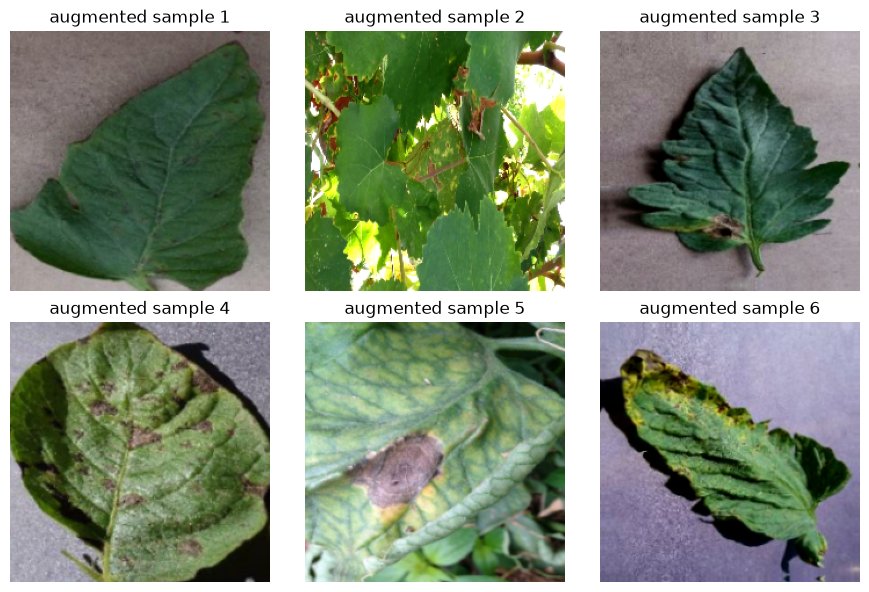

In [6]:
train_ds = dm.get_dataset("train", training=True)
x_batch, y_batch = next(iter(train_ds))

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for i, ax in enumerate(axes.flat):
    img = x_batch[i].numpy()
    ax.imshow(np.clip(img, 0, 255).astype("uint8"))
    ax.set_title(f"augmented sample {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Train all three strategies

In [7]:
train_script = PROJECT_ROOT / "scripts" / "train_script.py"
env = {**os.environ, "PYTHONPATH": str(PROJECT_ROOT), "PYTHONUNBUFFERED": "1"}

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("No GPU attached: switch to a GPU Colab server before training.")

def run_training(strat: str) -> None:
    """Runs one training job and streams its output live (epoch lines, warnings, errors)."""
    cmd = [sys.executable, str(train_script),
           "--config", str(PROJECT_ROOT / "configs" / "base.yaml"),
           "--model", MODEL, "--strategy", strat]
    with subprocess.Popen(cmd, cwd=PROJECT_ROOT, env=env, text=True, bufsize=1,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT) as proc:
        for line in proc.stdout:
            print(line, end="", flush=True)
    if proc.returncode != 0:
        raise RuntimeError(f"{strat} failed with exit code {proc.returncode} (see output above)")

runs = {}
for strat in STRATEGIES:
    print(f"\n========== {strat} ==========", flush=True)
    run_training(strat)

    run_dir = PROJECT_ROOT / "results" / f"{MODEL}_{strat}_s{CFG['seed']}"
    metrics = json.loads((run_dir / "metrics.json").read_text())
    history_df = pd.read_csv(run_dir / "history.csv")

    runs[strat] = {
        "dir": run_dir,
        "metrics": metrics,
        "history": history_df.to_dict(orient="list"),
    }
    print(json.dumps(metrics, indent=2))


========== feature_extraction ==========
I0000 00:00:1794617967.570682    1656 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794617972.928055    1656 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:09:00.0, compute capability: 8.6
/home/sloth/plant-disease-tl/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
Epoch 1/15
I0000 00:00:1794617984.655502    1773 service.cc:153] XLA service 

## 4. Comparison table

,macro_f1,accuracy,macro_precision,macro_recall,auc_macro_ovr,trainable_params,total_params,train_seconds,epochs_run
feature_extraction,0.898921,0.884615,0.895336,0.907670,0.995032,17685.0,27882645.0,640,15.0
partial_ft,0.974582,0.971782,0.974193,0.975521,0.999748,7146261.0,27882645.0,1493,30.0
full_ft,0.986524,0.986664,0.985513,0.987731,0.999737,27882645.0,27882645.0,2119,18.0


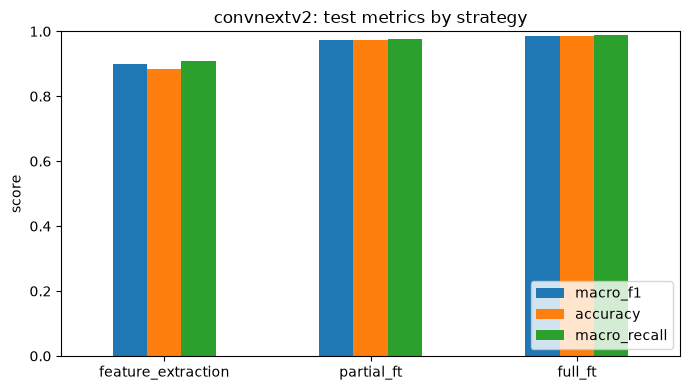

In [8]:
metric_cols = (
    "macro_f1", "accuracy", "macro_precision", "macro_recall", "auc_macro_ovr",
    "trainable_params", "total_params", "train_seconds", "epochs_run",
)
summary = pd.DataFrame({
    s: {k: r["metrics"][k] for k in metric_cols}
    for s, r in runs.items()
}).T
summary["train_seconds"] = summary["train_seconds"].round(0).astype(int)
display(summary)

ax = summary[["macro_f1", "accuracy", "macro_recall"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel("score")
ax.set_title(f"{MODEL}: test metrics by strategy")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Macro-F1 by strategy

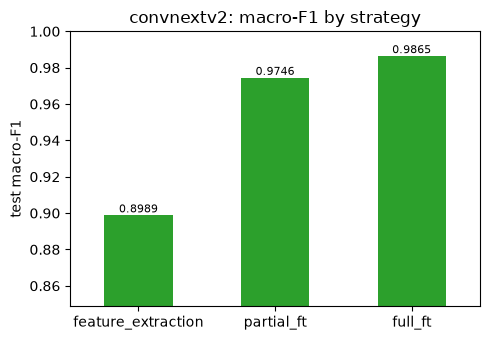

In [9]:
ax = summary["macro_f1"].plot.bar(figsize=(5, 3.5), rot=0, color="tab:green")
ax.set_ylim(max(0.0, summary["macro_f1"].min() - 0.05), 1.0)
ax.set_ylabel("test macro-F1")
ax.set_title(f"{MODEL}: macro-F1 by strategy")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Training curves

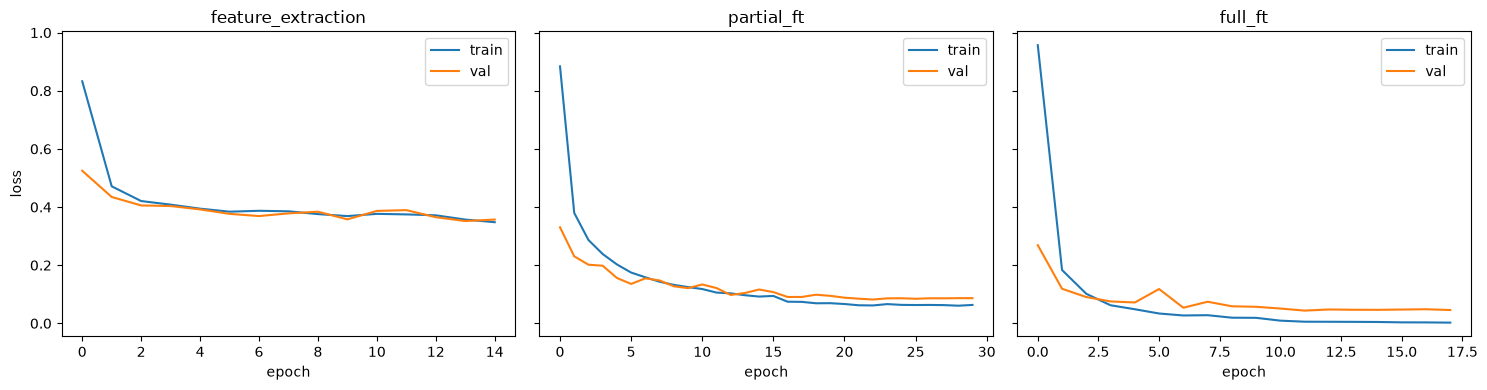

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (s, r) in zip(axes, runs.items()):
    h = r["history"]
    ax.plot(h["loss"], label="train")
    ax.plot(h["val_loss"], label="val")
    ax.set_title(s)
    ax.set_xlabel("epoch")
    ax.legend()

axes[0].set_ylabel("loss")
plt.tight_layout()
plt.show()

## 7. Confusion matrices (test set)

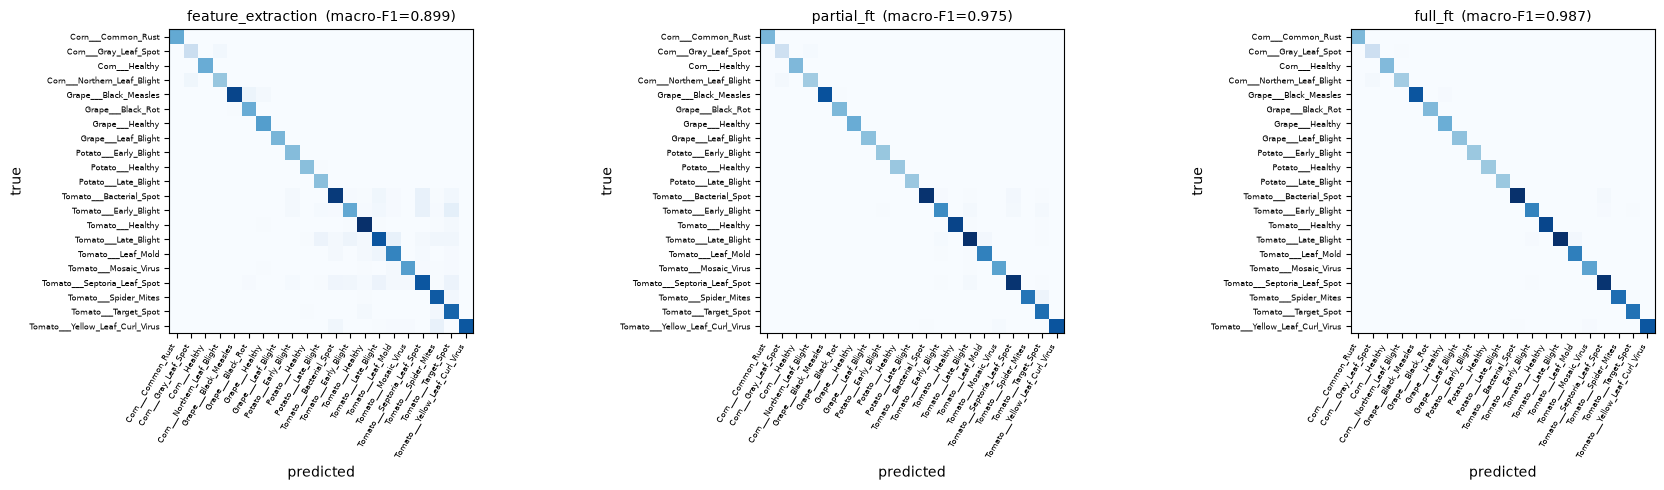

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (s, r) in zip(axes, runs.items()):
    cm = pd.read_csv(Path(r["dir"]) / "confusion_matrix.csv", index_col=0)
    ax.imshow(cm.values, cmap="Blues")
    ax.set_title(f"{s}  (macro-F1={r['metrics']['macro_f1']:.3f})", fontsize=10)
    ax.set_xticks(range(len(cm)))
    ax.set_xticklabels(cm.columns, rotation=60, ha="right", fontsize=6)
    ax.set_yticks(range(len(cm)))
    ax.set_yticklabels(cm.index, fontsize=6)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")

plt.tight_layout()
plt.show()

## 8. Grad-CAM on the best run

best strategy: full_ft  ->  /home/sloth/plant-disease-tl/results/convnextv2_full_ft_s42
Grad-CAM target layer: convnextv2_tiny


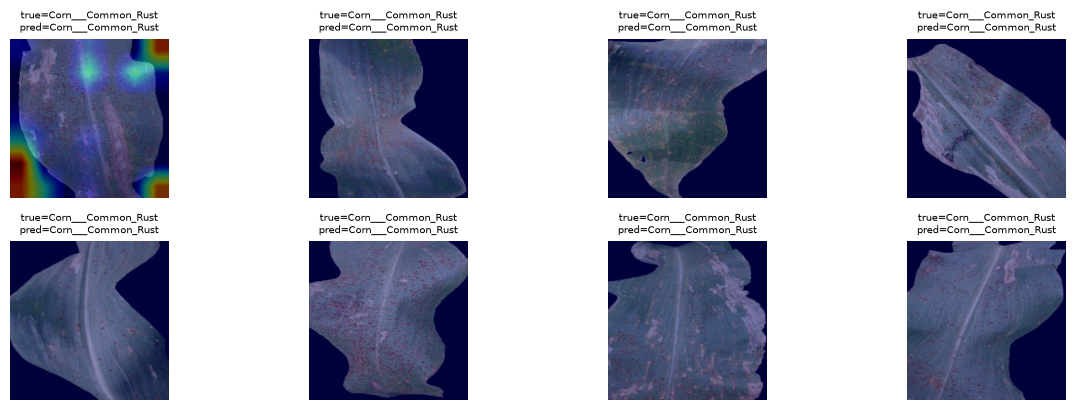

In [15]:
best_strat = summary["macro_f1"].idxmax()
best_dir = Path(runs[best_strat]["dir"])
print(f"best strategy: {best_strat}  ->  {best_dir}")

best_model = keras.models.load_model(best_dir / "best.keras", compile=False)
explainer = GradCAMExplainer(best_model)
print(f"Grad-CAM target layer: {explainer.target_name}")

test_ds = dm.get_dataset("test", training=False)
idx_to_class = {v: k for k, v in class_to_idx.items()}

n_show = 8
shown = 0
fig, axes = plt.subplots(2, n_show // 2, figsize=(n_show * 1.6, 4.2))

for x_b, y_b in test_ds:
    if shown >= n_show:
        break
    preds = best_model.predict(x_b, verbose=0).argmax(axis=1)
    for i in range(x_b.shape[0]):
        if shown >= n_show:
            break
        img = x_b[i].numpy()
        pred = int(preds[i])
        cam = explainer.generate_heatmap(img, pred)
        
        ax = axes.flat[shown]
        ax.imshow(np.clip(img, 0, 255).astype("uint8"))
        ax.imshow(cam, cmap="jet", alpha=0.45)
        ax.set_title(f"true={idx_to_class[int(y_b[i])]}\npred={idx_to_class[pred]}", fontsize=7)
        ax.axis("off")
        shown += 1

plt.tight_layout()
plt.show()

## 9. Summary

In [13]:
print(f"{'strategy':<20}{'macro-F1':>10}{'accuracy':>10}{'AUC':>8}{'params':>12}{'time(s)':>10}")
for s, r in runs.items():
    m = r["metrics"]
    print(
        f"{s:<20}{m['macro_f1']:>10.4f}{m['accuracy']:>10.4f}{m['auc_macro_ovr']:>8.4f}"
        f"{m['trainable_params']:>12,}{m['train_seconds']:>10.0f}"
    )
print(f"\nArtifacts under results/{MODEL}_<strategy>_s{CFG['seed']}/")

strategy              macro-F1  accuracy     AUC      params   time(s)
feature_extraction      0.8989    0.8846  0.9950      17,685       640
partial_ft              0.9746    0.9718  0.9997   7,146,261      1493
full_ft                 0.9865    0.9867  0.9997  27,882,645      2119

Artifacts under results/convnextv2_<strategy>_s42/
